In [1]:
using MAT, DataFrames, Statistics, Plots, LinearAlgebra, JLD2


In [2]:
include("./blp_optimize/blp_new.jl")
using .blp

In [3]:

d1 = matread("../build/input/public/simulation/10markets3products.mat")
d2 = matread("../build/input/public/simulation/100markets3products.mat")
d3 = matread("../build/input/public/simulation/100markets5products.mat")
Base.active_project()

"/Users/erickom/.julia/environments/v1.12/Project.toml"

In [4]:
function process_data(d)

    J, T = size(d["P_opt"])
    p = reshape(d["P_opt"], (T*J,1));
    shares = reshape(d["shares"], (T*J,1));
    X = d["x1"]; #JTxk
    alphas = d["alphas"]; #TxR
    errors = log.(d["alphas"] .- 1);
    xi = d["xi_all"]; #JxR
    w = d["w"]; #JTx1
    Z_cost = d["Z"]; #JTx1
    omega = d["eta"]; #JTx1

    data = blp.BLPData(T, J, X, p, shares, errors)
    model = blp.BLPDemand(BLPData = data)

    model.xi_real = xi
    model.cost = gamma[1] .+ (gamma[2] * w + gamma[3] * Z_cost + omega) ;
    model.markup .= ((model.p - model.cost)./model.p ) ;
    model.profit = (model.p - model.cost) .* model.shares
    return model

end

process_data (generic function with 1 method)

In [5]:
beta = [5,1,1];
alpha_bar = -1;
gamma = [2,1,1];
sigma = 1.0;

In [6]:
model_ls = process_data(d1);
model = process_data(d2);
model_mp = process_data(d3);

In [7]:
# The errors for the model_mp model will be replaced by the errors in the original models to make a proper comparison
model_mp.errors = model.errors;

In [8]:
# Assigning the true parameters
model.beta .= vcat(beta,[alpha_bar]) ; 
model.sigma = sigma ;

model_mp.beta .= vcat(beta,[alpha_bar]) ; 
model_mp.sigma = sigma ;

In [9]:
# Computing delta
delta = model.X_all * model.beta + model.xi_real ;
delta_mp = model_mp.X_all * model_mp.beta + model_mp.xi_real ;

In [10]:
blp.simulate_BLP!(model, delta = delta, sigma = sigma, all = true);
blp.simulate_BLP!(model_mp, delta = delta_mp, sigma = sigma, all = true);

#### Question 6

In [11]:
using Plots
using LaTeXStrings
using Statistics
using ColorSchemes
using StatsPlots

##### A) Compare price, markups and profits

In the case with more products, prices go down, but interestingly markups seem to mantain and profits go up. The latter could be a consequence of lower costs rather than a market equilibrium effect.

In [12]:
describe(DataFrame(reshape(model.p, (model.J, model.T,))', :auto), :mean, :std, :median, :q25, :q75)

Row,variable,mean,std,median,q25,q75
,Symbol,Float64,Float64,Float64,Float64,Float64
1,x1,3.88577,1.40637,3.86152,2.85858,4.67563
2,x2,2.45794,1.07285,2.34746,1.73001,3.09984
3,x3,2.73594,1.1797,2.67599,1.83526,3.52928


In [13]:
describe(DataFrame(reshape(model_mp.p, (model_mp.J, model_mp.T,))', :auto), :mean, :std, :median, :q25, :q75)

Row,variable,mean,std,median,q25,q75
,Symbol,Float64,Float64,Float64,Float64,Float64
1,x1,1.95741,1.37218,1.86431,0.990264,2.84981
2,x2,2.17163,1.2935,2.2334,1.09456,2.95268
3,x3,1.2274,1.05437,1.10291,0.55904,2.00339
4,x4,1.14482,1.33106,0.763605,0.23765,1.9061
5,x5,2.9542,1.30592,2.96422,2.07107,3.9727


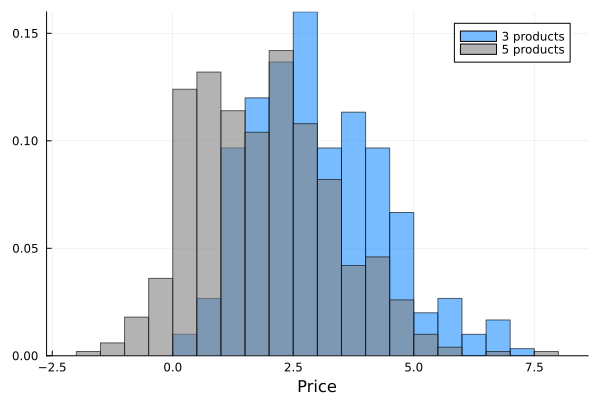

In [14]:
histogram(
    normalize = :probability,
    model.p,
    bins = 25,
    alpha = 0.6,
    color = :dodgerblue,
    edgecolor = :darkblue,
    xlabel = "Price",
    label = "3 products"
)

histogram!(
    normalize = :probability,
    model_mp.p,
    bins = 25,
    alpha = 0.6,
    color = :gray,
    edgecolor = :darkred,
    xlabel = "Price",
    label = "5 products"
)

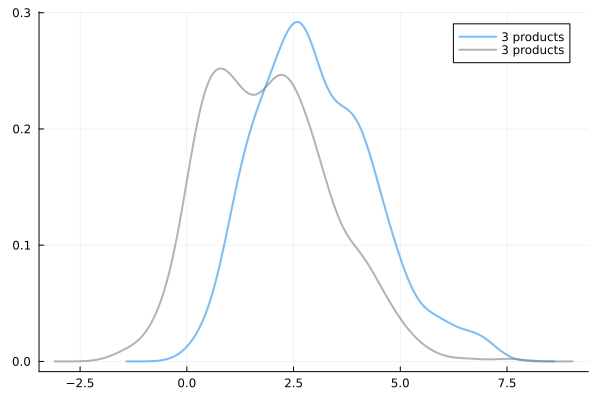

In [15]:
density(model.p, 
    alpha = 0.6,
    color = :dodgerblue,
    edgecolor = :darkblue,
    label="3 products", 
    lw=2)

density!(model_mp.p, 
    alpha = 0.6,
    color = :gray,
    edgecolor = :black,
    label="3 products", 
    lw=2)

In [16]:
describe(DataFrame(reshape(model.markup, (model.J, model.T,))', :auto), :mean, :std, :median, :q25, :q75)

Row,variable,mean,std,median,q25,q75
,Symbol,Float64,Float64,Float64,Float64,Float64
1,x1,0.246187,0.165551,0.199706,0.156673,0.259881
2,x2,0.684267,0.877215,0.43892,0.270819,0.828768
3,x3,0.484761,0.56423,0.286734,0.222394,0.56477


In [17]:
describe(DataFrame(reshape(model_mp.markup, (model_mp.J, model_mp.T,))', :auto), :mean, :std, :median, :q25, :q75, :min, :max)

Row,variable,mean,std,median,q25,q75,min,max
,Symbol,Float64,Float64,Float64,Float64,Float64,Float64,Float64
1,x1,0.947322,3.61643,0.327488,0.228102,0.636039,-4.09559,34.3962
2,x2,-7.7537,84.6688,0.299379,0.223896,0.541855,-845.904,6.63568
3,x3,1.23228,7.02946,0.517821,0.295779,1.15394,-31.0054,45.1595
4,x4,0.976069,5.54463,0.579816,0.250426,1.8154,-23.7571,25.3123
5,x5,0.317444,0.572471,0.232852,0.184265,0.312278,-1.08501,5.62887


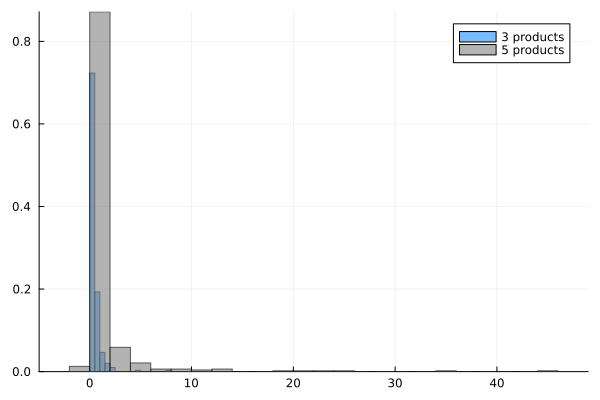

In [18]:
histogram(
    normalize = :probability,
    model.markup,
    bins = 25,
    alpha = 0.6,
    color = :dodgerblue,
    edgecolor = :darkblue,
    label = "3 products"
)

histogram!(
    normalize = :probability,
    model_mp.markup[model_mp.markup .> -1, :],
    bins = 25,
    alpha = 0.6,
    color = :gray,
    edgecolor = :black,
    label = "5 products"
)

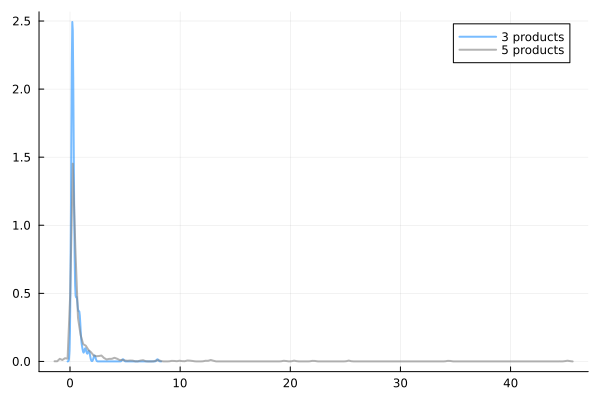

In [19]:
density(model.markup, 
    alpha = 0.6,
    color = :dodgerblue,
    edgecolor = :darkblue,
    label="3 products", 
    lw=2)

density!(
    model_mp.markup[model_mp.markup .> -1, :], 
    alpha = 0.6,
    color = :gray,
    edgecolor = :black,
    label="5 products", 
    lw=2)

In [20]:
describe(DataFrame(reshape(model.profit, (model.J, model.T,))', :auto), :mean, :std, :median, :q25, :q75)

Row,variable,mean,std,median,q25,q75
,Symbol,Float64,Float64,Float64,Float64,Float64
1,x1,0.0992899,0.177044,0.0282777,0.00691663,0.116808
2,x2,0.538401,0.603814,0.311193,0.100736,0.770478
3,x3,0.288319,0.390487,0.0999569,0.0333529,0.346653


In [21]:
describe(DataFrame(reshape(model_mp.profit, (model_mp.J, model_mp.T,))', :auto), :mean, :std, :median, :q25, :q75)

Row,variable,mean,std,median,q25,q75
,Symbol,Float64,Float64,Float64,Float64,Float64
1,x1,0.177263,0.408081,0.0232069,0.00458433,0.113644
2,x2,0.140031,0.27755,0.0174938,0.00205574,0.111185
3,x3,0.502255,0.75065,0.209402,0.0368337,0.536717
4,x4,0.424324,0.597818,0.177065,0.0494996,0.491452
5,x5,0.0271508,0.0691688,0.00329293,0.000564842,0.0162687


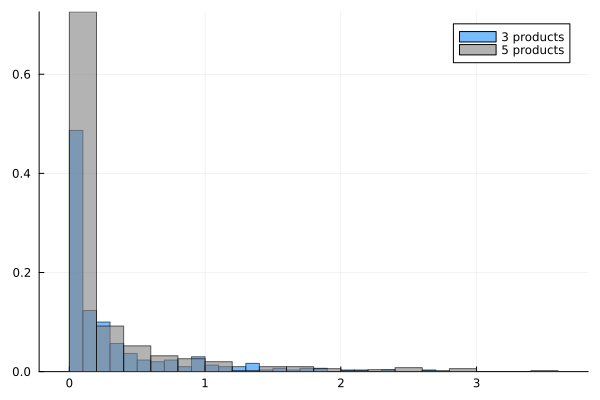

In [22]:
histogram(
    normalize = :probability,
    model.profit,
    bins = 25,
    alpha = 0.6,
    color = :dodgerblue,
    edgecolor = :darkblue,
    label = "3 products"
)

histogram!(
    normalize = :probability,
    model_mp.profit,
    bins = 25,
    alpha = 0.6,
    color = :gray,
    edgecolor = :black,
    label = "5 products"
)

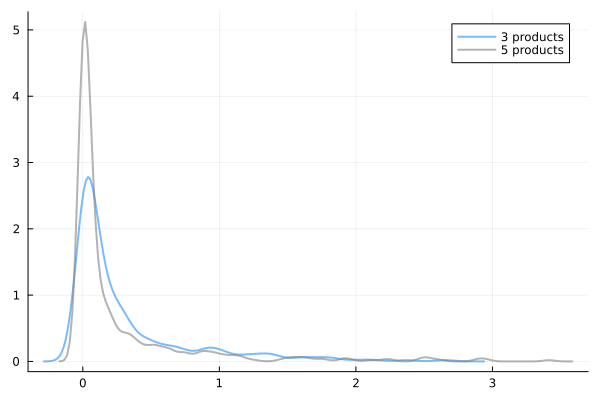

In [23]:
density(model.profit, 
    alpha = 0.6,
    color = :dodgerblue,
    edgecolor = :darkblue,
    label="3 products", 
    lw=2)

density!(
    model_mp.profit, 
    alpha = 0.6,
    color = :gray,
    edgecolor = :black,
    label="5 products", 
    lw=2)

##### B) Compare Consumer Surplus

In [24]:
# Simulated are real ones with real parameters
model.cs = model.cs_sim;
model.elas = model.elas_sim;
model_mp.cs = model_mp.cs_sim;

In [25]:
describe(DataFrame(model.cs, :auto), :mean, :std, :median, :q25, :q75)

Row,variable,mean,std,median,q25,q75
,Symbol,Float64,Float64,Float64,Float64,Float64
1,x1,1.31383,0.642036,1.25108,0.851205,1.72942


In [26]:
describe(DataFrame(model_mp.cs, :auto), :mean, :std, :median, :q25, :q75)

Row,variable,mean,std,median,q25,q75
,Symbol,Float64,Float64,Float64,Float64,Float64
1,x1,2.76488,0.747007,2.697,2.25767,3.22767


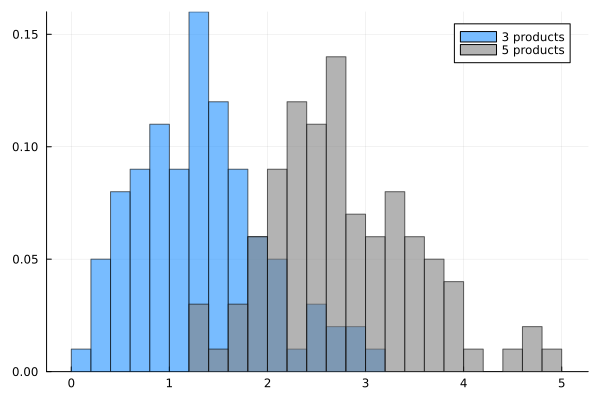

In [27]:
histogram(
    normalize = :probability,
    model.cs,
    bins = 25,
    alpha = 0.6,
    color = :dodgerblue,
    edgecolor = :darkblue,
    label = "3 products"
)

histogram!(
    normalize = :probability,
    model_mp.cs,
    bins = 25,
    alpha = 0.6,
    color = :gray,
    edgecolor = :black,
    label = "5 products"
)

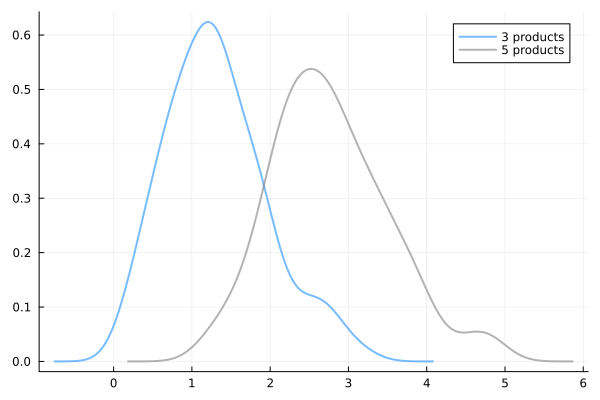

In [28]:
density(model.cs, 
    alpha = 0.6,
    color = :dodgerblue,
    edgecolor = :darkblue,
    label="3 products", 
    lw=2)

density!(
    model_mp.cs, 
    alpha = 0.6,
    color = :gray,
    edgecolor = :black,
    label="5 products", 
    lw=2)

##### C) Verification of simulations

In [29]:
describe(DataFrame(model.shares - model.shares_sim, :auto), :mean, :std, :median, :q25, :q75)

Row,variable,mean,std,median,q25,q75
,Symbol,Float64,Float64,Float64,Float64,Float64
1,x1,-3.01268e-18,7.23603e-17,0.0,-1.38778e-17,6.93889e-18


In [30]:
describe(DataFrame(model_mp.shares - model_mp.shares_sim, :auto), :mean, :std, :median, :q25, :q75)

Row,variable,mean,std,median,q25,q75
,Symbol,Float64,Float64,Float64,Float64,Float64
1,x1,6.41694e-6,0.00481279,6.75541e-6,-0.000778736,0.000821309


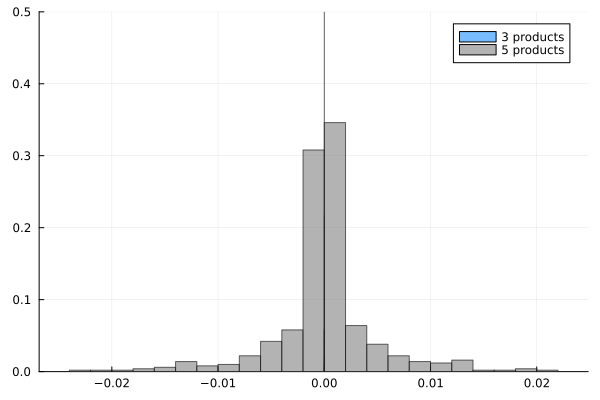

In [31]:
histogram(
    normalize = :probability,
    model.shares - model.shares_sim,
    bins = 25,
    alpha = 0.6,
    color = :dodgerblue,
    edgecolor = :darkblue,
    label = "3 products"
)

histogram!(
    normalize = :probability,
    model_mp.shares - model_mp.shares_sim,
    bins = 25,
    alpha = 0.6,
    color = :gray,
    edgecolor = :black,
    label = "5 products"
)

#### Question 7

##### A)

In [32]:
# E(ξ_{jt}x_{jt})
# Sample analog is 1/|JT| \sum_{jt} ξ_{jt}x_{jt}

# Features are assumed to be exogenous
model.xi_real' * model.X / (model.T*model.J), model_mp.xi_real' * model_mp.X / (model_mp.T*model_mp.J)



([0.04346103701850776 0.020741922402260037 0.03553150322946501], [0.05319247955708747 0.004006857253279954 0.03217115395231338])

In [33]:
# E(ξ_{jt}p_{jt})
# Sample analog is 1/|JT| \sum_{jt} ξ_{jt}p_{jt}
mean(model.p .* model.xi_real), mean(model_mp.p .* model_mp.xi_real)

(0.29495813714897284, 0.1741507848822992)

In [34]:
price_bar = blp.compute_hausman(model);
price_bar_mp = blp.compute_hausman(model_mp);

In [35]:
# E(ξ_{jt}p̄_{jt})
# Sample analog is 1/|JT| \sum_{jt} ξ_{jt} p̄_{jt}
mean(price_bar .* model.xi_real), mean(price_bar_mp .* model_mp.xi_real)

(0.14367954767468016, 0.0611274048731672)

##### B)

From these moments, the only theoretical valid are the first (xi times characteristics) and the last:
- The first moment is valid under the assumption that characteristics are exogenous. However, if products have enodgenous characteristics, that respond demand to xi, the instrument wouldn't be valid.
- The second moment is invalid, the prices are endogenous. Higher xi would imply more market power, which implies a greater price charged.
- The third moment is valid under specific assumption. The logic behind the Hausman instruments is that they are shocks that most shocks shared among markets come from cost/supply side. Demand shocks are specific to each market. Under that scenario, prices from other markets are reflecting supply side condiions that can help identify the demand in each market.

##### C)

In [36]:
X_rivals = blp.compute_blp(model);
X_rivals_mp = blp.compute_blp(model_mp);

In [37]:
mean(X_rivals .* model.xi_real, dims = 1), mean(X_rivals_mp .* model_mp.xi_real, dims = 1)

([0.045690439794137144 -0.008732902789657897], [0.11649356075511394 0.1560768173100903])

#### Question 8

##### A)

In [38]:
model_original = deepcopy(model)

Main.blp.BLPDemand(Main.blp.BLPData(100, 3, [1.0 0.6243472247093319 -0.3675935329234237; 1.0 0.1270525823227886 1.2737845739046483; … ; 1.0 0.1777924699713339 1.2819541386179385; 1.0 0.12895395588690017 1.3500392984244132], [6.342124353514706; 1.9304037342233142; … ; 2.3909451914239486; 1.5440226714681122;;], [5.1879758962001755e-5; 0.7184428240756918; … ; 0.19343063022875576; 0.6318247705454633;;], [-0.778340428081077 1.5860014874697206 … 1.1841193116853364 0.5825377025401334; -1.8058740935228996 0.9052572178649195 … 1.091591673538983 0.8694321550870392; … ; 1.3735359362936506 -0.2770972055353735 … -0.1220423654806788 0.8495783683864554; -0.9703732872407126 0.08268333470046725 … 0.25139606142215853 -0.04829348626510645]), 100, 3, [1.0 0.6243472247093319 -0.3675935329234237; 1.0 0.1270525823227886 1.2737845739046483; … ; 1.0 0.1777924699713339 1.2819541386179385; 1.0 0.12895395588690017 1.3500392984244132], [6.342124353514706; 1.9304037342233142; … ; 2.3909451914239486; 1.5440226714681

In [39]:
# Total utility for each simulation
model.util




300×500 Matrix{Float64}:
  -4.36396   -32.4279     -7.61449   -21.0961    …  -22.1767     -12.8079
   4.74563    -3.79643     3.75624    -0.347277      -0.676178     2.17547
   3.17414    -7.32069     1.95857    -3.08304       -3.48713      0.0164276
   5.07565    -0.611962    2.44707     4.32876       -1.85987     -0.39756
   4.53594     1.83854     3.28932     4.18172        1.24672      1.94023
   6.13886     3.47478     4.90764     5.78902   …    2.89026      3.57521
   0.835022   -1.87062     2.09574     3.16893        0.511424    -0.747347
   0.86344    -1.47309     1.95217     2.87895        0.583988    -0.503057
   2.43859     1.86189     2.70731     2.93606        2.36962      2.10131
 -22.5974     -1.38392   -24.2382     -7.34203       -1.69848     -0.47365
  -7.16503     2.96094    -7.94821     0.116917  …    2.81079      3.39544
 -11.3252      1.46969   -12.3148     -2.12395        1.27996      2.01872
  -6.73568    -0.629301   -7.51485    -0.386803      -0.700876    -1.190

In [40]:
model.X_all * model.beta + model.xi_real

300×1 Matrix{Float64}:
 -1.4518641019760865
  5.632010385203628
  4.263150150693943
  5.480568646894691
  4.727975252367814
  6.32852668685549
  4.1095050355533855
  3.6912078300770457
  3.1365382949109684
  0.13530108590994772
  3.6861180324693716
  2.3860066886297684
  2.0023149221826024
  ⋮
  3.210600704297366
  3.4169388341460767
  1.7310751335505226
  1.3296334430348735
  3.2198178904640957
  2.6374733223690496
  0.9965828784331713
  3.0556204805842095
  2.2903017718958654
  3.0440200931364525
  4.609945586530993
  4.994262609567306

In [41]:
# Delta comming from X_all*beta (includes centered parameter of the price)
model.delta

300×1 Matrix{Float64}:
 -1.4518641019760865
  5.632010385203628
  4.263150150693943
  5.480568646894691
  4.727975252367814
  6.32852668685549
  4.1095050355533855
  3.6912078300770457
  3.1365382949109684
  0.13530108590994772
  3.6861180324693716
  2.3860066886297684
  2.0023149221826024
  ⋮
  3.210600704297366
  3.4169388341460767
  1.7310751335505226
  1.3296334430348735
  3.2198178904640957
  2.6374733223690496
  0.9965828784331713
  3.0556204805842095
  2.2903017718958654
  3.0440200931364525
  4.609945586530993
  4.994262609567306

In [42]:
# Utility from the individual part
model.util .- model.delta

300×500 Matrix{Float64}:
  -2.9121    -30.9761     -6.16263   …   -5.23416   -20.7248    -11.3561
  -0.886378   -9.42844    -1.87577       -1.59316    -6.30819    -3.45654
  -1.08901   -11.5838     -2.30458       -1.95737    -7.75028    -4.24672
  -0.404919   -6.09253    -3.03349       -3.9017     -7.34043    -5.87813
  -0.192036   -2.88943    -1.43866       -1.85041    -3.48126    -2.78775
  -0.189664   -2.85374    -1.42089   …   -1.82756    -3.43826    -2.75332
  -3.27448    -5.98013    -2.01376      -13.9902     -3.59808    -4.85685
  -2.82777    -5.1643     -1.73904      -12.0816     -3.10722    -4.19427
  -0.697948   -1.27465    -0.429229      -2.98198    -0.766922   -1.03523
 -22.7327     -1.51922   -24.3735        -2.31932    -1.83379    -0.608951
 -10.8511     -0.725179  -11.6343    …   -1.1071     -0.875332   -0.290674
 -13.7112     -0.916318  -14.7009        -1.3989     -1.10605    -0.367289
  -8.738      -2.63162    -9.51716       -0.438769   -2.70319    -3.19292
   ⋮       

##### B)

We have the moments as follow. For a set of instruments Z:
$$E(Z_{jt} \xi_{jt}) = 0$$

In this case we know that the shares of the data are a function of $\sigma$ and $\delta_{jt}$. From the nested fixed point we know that: 

$$\delta = \delta_(\sigma, s)$$

Where $s_{jt}$ are the observed shares in the markets. Since we can recover $\xi_{jt}$ directly from a the residual of the projection of $\delta$ onto the space of $X$ using $Z$ as instruments, we can recover $\xi_{jr}$ as:

$$M_X^Z = I - (X'Z(W)Z'X)^{-1} (X'Z(W)Z')$$
$$\xi = M_X^Z \delta$$

Hence the GMM can be written as:

$$\min_{\sigma} \left(Z' M_X^Z \delta(\sigma, s)\right)' W \left(Z' M_X^Z \delta(\sigma, s)\right)$$


##### C)

In [43]:
Z = hcat(model.X, X_rivals);
W = inv(Z' * Z)

model.Z = Z
model.W = W


5×5 Matrix{Float64}:
  0.0392677    -0.0229455    -0.000345716  -0.0229455    -0.000345716
 -0.0229455     0.0414715     0.000377454   0.00125728   -2.1081e-5
 -0.000345716   0.000377454   0.0036785    -2.1081e-5    -0.00012337
 -0.0229455     0.00125728   -2.1081e-5     0.0213644     0.000178187
 -0.000345716  -2.1081e-5    -0.00012337    0.000178187   0.00177756

In [44]:
function get_estimates!(model, name; toler = 1e-3, max_iter = 1000, Ns = 1)
    path =  "models_quick/$(name).jdl2"
    if !isfile(path)
        if  typeof(model) == blp.BLPDemand
            blp.estimate_blp!(model, toler = toler, max_iter = max_iter, Ns = Ns)
        elseif typeof(model) == blp.BLP
            blp.estimate_blp_joint!(model, toler = toler, max_iter = max_iter, Ns = Ns)
        end
        jldsave(path; model = model)
        return model
    else
        model = load(path)["model"]
        return model
    end
end

get_estimates! (generic function with 1 method)

In [45]:
model = get_estimates!(model, "model_nh");
model_h = get_estimates!(model, "model");

In [46]:
model_h.params

5×1 Matrix{Float64}:
  4.983146073454243
  0.9669717678056539
  1.0368555354953632
 -0.9715250562888574
  1.006474178717289

In [47]:
model.params

5×1 Matrix{Float64}:
  5.590478114427768
  1.1000713863486844
  1.0816603603205672
 -1.168886236916529
  1.0543456475575683

In [48]:
model.Z

300×5 Matrix{Float64}:
 1.0  0.624347   -0.367594   0.958816   2.42568
 1.0  0.127053    1.27378    1.45611    0.784306
 1.0  0.831763    1.1519     0.7514     0.906191
 1.0  0.411836    1.21314    1.55       0.864108
 1.0  0.802276   -0.196385   1.15956    2.27363
 1.0  0.747726    1.06049    1.21411    1.01675
 1.0  0.344467    0.400508   0.870635   0.4146
 1.0  0.808729    1.01171    0.406373  -0.196602
 1.0  0.0619061  -0.59711    1.1532     1.41222
 1.0  0.231617    1.47189    1.17692    1.32932
 1.0  0.553895    1.17418    0.854641   1.62703
 1.0  0.623025    0.155137   0.785512   2.64607
 1.0  0.202199    0.947146   0.89269    1.00881
 ⋮                                     
 1.0  0.364622    0.149427   0.556088  -0.984794
 1.0  0.144008   -0.290763   0.776702  -0.544605
 1.0  0.41208    -0.694031   0.50863   -0.141336
 1.0  0.675931   -1.45306    1.048      0.692162
 1.0  0.727197    0.909643   0.996732  -1.67054
 1.0  0.320802   -0.21748    1.40313   -0.54342
 1.0  0.650807    

In [49]:
model

Main.blp.BLPDemand(Main.blp.BLPData(100, 3, [1.0 0.6243472247093319 -0.3675935329234237; 1.0 0.1270525823227886 1.2737845739046483; … ; 1.0 0.1777924699713339 1.2819541386179385; 1.0 0.12895395588690017 1.3500392984244132], [6.342124353514706; 1.9304037342233142; … ; 2.3909451914239486; 1.5440226714681122;;], [5.1879758962001755e-5; 0.7184428240756918; … ; 0.19343063022875576; 0.6318247705454633;;], [-0.778340428081077 1.5860014874697206 … 1.1841193116853364 0.5825377025401334; -1.8058740935228996 0.9052572178649195 … 1.091591673538983 0.8694321550870392; … ; 1.3735359362936506 -0.2770972055353735 … -0.1220423654806788 0.8495783683864554; -0.9703732872407126 0.08268333470046725 … 0.25139606142215853 -0.04829348626510645]), 100, 3, [1.0 0.6243472247093319 -0.3675935329234237; 1.0 0.1270525823227886 1.2737845739046483; … ; 1.0 0.1777924699713339 1.2819541386179385; 1.0 0.12895395588690017 1.3500392984244132], [6.342124353514706; 1.9304037342233142; … ; 2.3909451914239486; 1.5440226714681

##### D)

In [50]:
blp.simulate_BLP!(model, all = true);

In [51]:
model.markup_sim

300×1 Matrix{Float64}:
 0.10605951625855273
 1.0913132061299837
 0.24111843067188674
 0.26489093182463314
 0.3836081646112792
 1.202914919922097
 0.28842148134875273
 0.2939215145663681
 1.691695303471021
 0.1597298800390627
 0.8556489845471893
 0.26264354914266597
 0.21113179274681468
 ⋮
 0.3314191100549295
 1.0034574569906318
 0.22329040505640513
 0.2494767798493284
 0.27436905309420284
 0.1922279087351234
 0.1555657095477013
 0.3322962536841197
 0.5248738297571133
 0.23594142330777634
 0.2850052241058893
 0.8463078146555995

In [52]:
model.markup

300×1 Matrix{Float64}:
 0.11817311394301196
 1.147561704852202
 0.261513187093628
 0.2881155781815464
 0.41668693536553975
 1.28823511828109
 0.31262484558485737
 0.3184654047658585
 1.7932532767448315
 0.17644175005552523
 0.9022908605070861
 0.2859514287156175
 0.2304505106540529
 ⋮
 0.35971258955077173
 1.0611921461357536
 0.24473535641971747
 0.2701627763444155
 0.2966204324338854
 0.2097815738538509
 0.1714095733630758
 0.3591691604884945
 0.561915913787402
 0.25620691825243774
 0.30829679069789273
 0.9028335268221344

In [53]:
model.params

5×1 Matrix{Float64}:
  5.590478114427768
  1.1000713863486844
  1.0816603603205672
 -1.168886236916529
  1.0543456475575683

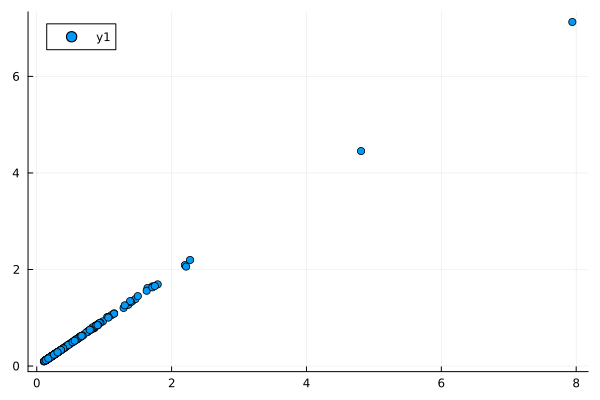

In [54]:
scatter(model_original.markup, model.markup_sim)

In [55]:
DataFrame(original = vec(model_original.markup), simulated =  vec(model.markup_sim))

Row,original,simulated
,Float64,Float64
1,0.118173,0.10606
2,1.14756,1.09131
3,0.261513,0.241118
4,0.288116,0.264891
5,0.416687,0.383608
6,1.28824,1.20291
7,0.312625,0.288421
8,0.318465,0.293922
9,1.79325,1.6917


In [56]:
model.elas_sim

300×3 Matrix{Float64}:
 -9.42867       2.34225    0.629723
  0.000555681  -0.916327   0.651321
  0.000729528   3.1805    -4.14734
 -3.77514       0.297032   1.46908
  0.422545     -2.60683    2.18493
  0.418403      0.43744   -0.831314
 -3.46715       0.98425    0.46552
  1.3609       -3.40227    0.513277
  0.74745       0.59604   -0.591123
 -6.26057       2.31293    0.633705
  0.0402531    -1.1687     0.601221
  0.0468601     2.55455   -3.80744
 -4.73638       1.75824    1.19329
  ⋮                       
 -3.01733       1.36613    0.21434
  0.872625     -0.996554   0.164989
  1.04676       1.26144   -4.47847
 -4.00839       2.37943    1.21409
  0.558984     -3.64473    1.40485
  0.549686      2.7075    -5.20216
 -6.42815       2.09519    0.99757
  0.195299     -3.00936    1.13469
  0.138184      1.68622   -1.90522
 -4.23834       1.06141    2.049
  0.229633     -3.50871    2.00517
  0.210154      0.950597  -1.1816

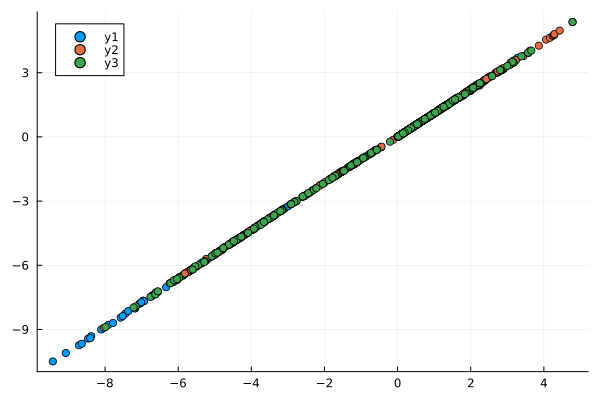

In [57]:
scatter(model_original.elas, model.elas_sim)

In [58]:
DataFrame(original =vec(model.elas), simulated =  vec(model.elas_sim))

Row,original,simulated
,Float64,Float64
1,0.0,-9.42867
2,0.0,0.000555681
3,0.0,0.000729528
4,2.122e-314,-3.77514
5,0.0,0.422545
6,0.0,0.418403
7,2.122e-314,-3.46715
8,0.0,1.3609
9,0.0,0.74745


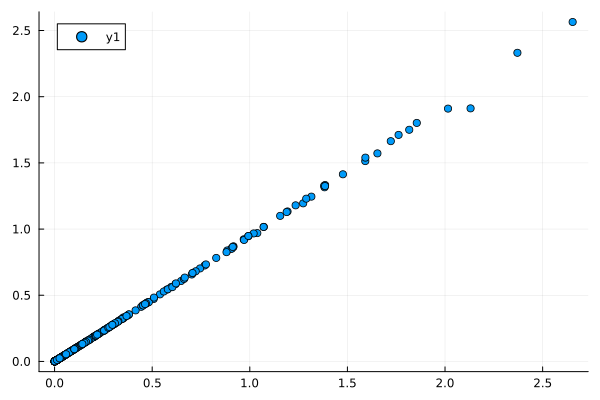

In [59]:
scatter(model_original.profit, model.profit_sim)

In [60]:
DataFrame(original = vec(model_original.profit), simulated =  vec(model.profit_sim))

Row,original,simulated
,Float64,Float64
1,3.88822e-5,3.48965e-5
2,1.59154,1.51353
3,0.0742735,0.0684811
4,0.0661418,0.0608101
5,0.0672433,0.0619052
6,1.03837,0.969602
7,0.161126,0.148652
8,0.118709,0.10956
9,0.575625,0.543025


##### E)

In [61]:
p_bar_ls = blp.compute_hausman(model_ls);
X_rivals_ls = blp.compute_blp(model_ls);

In [62]:
Z_ls = hcat(model_ls.X, p_bar_ls, X_rivals_ls);
W_ls = inv(Z_ls' * Z_ls);

In [63]:
model_ls.Z = Z_ls
model_ls.W = W_ls

6×6 Matrix{Float64}:
  4.91113    -0.419647    0.0928196  -1.62872    -0.543197    0.109699
 -0.419647    0.641522   -0.0670866  -0.0402584   0.191814   -0.0179812
  0.0928196  -0.0670866   0.045025   -0.0196178  -0.0198865   0.0141968
 -1.62872    -0.0402584  -0.0196178   0.650486    0.0090857  -0.0263591
 -0.543197    0.191814   -0.0198865   0.0090857   0.41583    -0.0443248
  0.109699   -0.0179812   0.0141968  -0.0263591  -0.0443248   0.0299857

In [64]:
model_ls = get_estimates!(model_ls, "model_ls");

In [65]:
model_ls.params

5×1 Matrix{Float64}:
  4.276379762846109
  0.525064689925678
  1.0054463158674336
 -1.0567766742283766
  0.1000000033926718

##### F)

In [66]:
model_inc = deepcopy(model)

Main.blp.BLPDemand(Main.blp.BLPData(100, 3, [1.0 0.6243472247093319 -0.3675935329234237; 1.0 0.1270525823227886 1.2737845739046483; … ; 1.0 0.1777924699713339 1.2819541386179385; 1.0 0.12895395588690017 1.3500392984244132], [6.342124353514706; 1.9304037342233142; … ; 2.3909451914239486; 1.5440226714681122;;], [5.1879758962001755e-5; 0.7184428240756918; … ; 0.19343063022875576; 0.6318247705454633;;], [-0.778340428081077 1.5860014874697206 … 1.1841193116853364 0.5825377025401334; -1.8058740935228996 0.9052572178649195 … 1.091591673538983 0.8694321550870392; … ; 1.3735359362936506 -0.2770972055353735 … -0.1220423654806788 0.8495783683864554; -0.9703732872407126 0.08268333470046725 … 0.25139606142215853 -0.04829348626510645]), 100, 3, [1.0 0.6243472247093319 -0.3675935329234237; 1.0 0.1270525823227886 1.2737845739046483; … ; 1.0 0.1777924699713339 1.2819541386179385; 1.0 0.12895395588690017 1.3500392984244132], [6.342124353514706; 1.9304037342233142; … ; 2.3909451914239486; 1.5440226714681

In [67]:
Z_inc = hcat(model_inc.X_all, X_rivals);
W_inc = inv(Z_inc' * Z_inc);

model_inc.Z = Z_inc
model_inc.W = W_inc

6×6 Matrix{Float64}:
  0.0551105    -0.0199691     0.000257539  …  -0.0238846    -0.00105304
 -0.0199691     0.0420307     0.000490789      0.00108085   -0.000153967
  0.000257539   0.000490789   0.00370147      -5.68392e-5   -0.000150303
 -0.00541042   -0.00101646   -0.000206015      0.000320705   0.000241555
 -0.0238846     0.00108085   -5.68392e-5       0.0214201     0.000220114
 -0.00105304   -0.000153967  -0.000150303  …   0.000220114   0.00180914

In [68]:
model_inc = get_estimates!(model_inc, "model_inc");

In [69]:
model_inc.opt_res

1-element Vector{Any}:
  * Status: success

 * Candidate solution
    Final objective value:     3.702105e-01

 * Found with
    Algorithm:     Fminbox with L-BFGS

 * Convergence measures
    |x - x'|               = 5.35e-11 ≰ 0.0e+00
    |x - x'|/|x'|          = 5.27e-11 ≰ 0.0e+00
    |f(x) - f(x')|         = 1.30e-13 ≰ 0.0e+00
    |f(x) - f(x')|/|f(x')| = 3.51e-13 ≰ 0.0e+00
    |g(x)|                 = 1.54e-11 ≤ 1.0e-08

 * Work counters
    Seconds run:   6  (vs limit Inf)
    Iterations:    4
    f(x) calls:    17
    ∇f(x) calls:   17
    ∇f(x)ᵀv calls: 0


In [70]:
model_inc.sigma


1.014746256154887

In [71]:
model.params

5×1 Matrix{Float64}:
  5.590478114427768
  1.1000713863486844
  1.0816603603205672
 -1.168886236916529
  1.0543456475575683

In [72]:
model_inc.params

5×1 Matrix{Float64}:
  4.866274948956785
  0.9444759392786807
  1.036167857669557
 -0.9244962764462634
  1.014746256154887

In [73]:
model_ls.params

5×1 Matrix{Float64}:
  4.276379762846109
  0.525064689925678
  1.0054463158674336
 -1.0567766742283766
  0.1000000033926718

#### Question 9

##### A)

In [74]:
model_ss = deepcopy(model)

Main.blp.BLPDemand(Main.blp.BLPData(100, 3, [1.0 0.6243472247093319 -0.3675935329234237; 1.0 0.1270525823227886 1.2737845739046483; … ; 1.0 0.1777924699713339 1.2819541386179385; 1.0 0.12895395588690017 1.3500392984244132], [6.342124353514706; 1.9304037342233142; … ; 2.3909451914239486; 1.5440226714681122;;], [5.1879758962001755e-5; 0.7184428240756918; … ; 0.19343063022875576; 0.6318247705454633;;], [-0.778340428081077 1.5860014874697206 … 1.1841193116853364 0.5825377025401334; -1.8058740935228996 0.9052572178649195 … 1.091591673538983 0.8694321550870392; … ; 1.3735359362936506 -0.2770972055353735 … -0.1220423654806788 0.8495783683864554; -0.9703732872407126 0.08268333470046725 … 0.25139606142215853 -0.04829348626510645]), 100, 3, [1.0 0.6243472247093319 -0.3675935329234237; 1.0 0.1270525823227886 1.2737845739046483; … ; 1.0 0.1777924699713339 1.2819541386179385; 1.0 0.12895395588690017 1.3500392984244132], [6.342124353514706; 1.9304037342233142; … ; 2.3909451914239486; 1.5440226714681

In [75]:
Z_ss = hcat(model_ss.X, price_bar, X_rivals, d2["w"])
W_ss = inv(Z_ss' * Z_ss)

7×7 Matrix{Float64}:
  2.24406       0.00846886    0.00100756   …  -0.000451011   0.562425
  0.00846886    0.0423258     0.000509806     -7.91695e-5    0.00650677
  0.00100756    0.000509806   0.00371076      -0.000139167  -7.37061e-5
 -0.754328     -0.0106779    -0.00044357       2.63024e-5   -0.192682
 -0.039426      0.000819185  -8.77119e-5       0.000207258  -0.00345092
 -0.000451011  -7.91695e-5   -0.000139167  …   0.00178544    0.000182794
  0.562425      0.00650677   -7.37061e-5       0.000182794   0.149052

In [76]:
model_ss.Z = Z_ss
model_ss.W = W_ss

7×7 Matrix{Float64}:
  2.24406       0.00846886    0.00100756   …  -0.000451011   0.562425
  0.00846886    0.0423258     0.000509806     -7.91695e-5    0.00650677
  0.00100756    0.000509806   0.00371076      -0.000139167  -7.37061e-5
 -0.754328     -0.0106779    -0.00044357       2.63024e-5   -0.192682
 -0.039426      0.000819185  -8.77119e-5       0.000207258  -0.00345092
 -0.000451011  -7.91695e-5   -0.000139167  …   0.00178544    0.000182794
  0.562425      0.00650677   -7.37061e-5       0.000182794   0.149052

In [77]:
model_ss = get_estimates!(model_ss, "model_ss");

##### B)

In [78]:
model_ls_ss = deepcopy(model_ls)
Z_ls_ss = hcat(model_ls_ss.X, p_bar_ls, X_rivals_ls, d1["w"])
W_ls_ss = inv(Z_ls_ss' * Z_ls_ss)


7×7 Matrix{Float64}:
  5.4207    -0.425996     0.104826    …   0.120086    -0.411559
 -0.425996   0.641601    -0.0672362      -0.0181106    0.00512803
  0.104826  -0.0672362    0.0453079       0.0144416   -0.00969716
 -1.9235    -0.0365854   -0.0265634      -0.0323676    0.238078
 -0.535018   0.191712    -0.0196938      -0.0441581   -0.00660594
  0.120086  -0.0181106    0.0144416   …   0.0301974   -0.00838891
 -0.411559   0.00512803  -0.00969716     -0.00838891   0.332395

In [79]:
model_ls_ss.Z = Z_ls_ss
model_ls_ss.W = W_ls_ss

7×7 Matrix{Float64}:
  5.4207    -0.425996     0.104826    …   0.120086    -0.411559
 -0.425996   0.641601    -0.0672362      -0.0181106    0.00512803
  0.104826  -0.0672362    0.0453079       0.0144416   -0.00969716
 -1.9235    -0.0365854   -0.0265634      -0.0323676    0.238078
 -0.535018   0.191712    -0.0196938      -0.0441581   -0.00660594
  0.120086  -0.0181106    0.0144416   …   0.0301974   -0.00838891
 -0.411559   0.00512803  -0.00969716     -0.00838891   0.332395

In [80]:
model_ls_ss = get_estimates!(model_ls_ss, "model_ss");

##### C)

In [81]:
# In the code, now the BLP Model has an Omega argument that reflects the ownership
# Perfect competition uses the matrix of zeros, where costs are equal to prices

##### D)

We will be using the results including cost shifts instruments, for each scenario we create a new object

In [82]:
model_coll = deepcopy(model_ss);
model_coll.Omega = ones(model_coll.J, model_coll.J);
blp.simulate_BLP!(model_coll, all=true);


In [83]:
DataFrame(original = vec(model.elas), simulated =  vec(model.elas))

Row,original,simulated
,Float64,Float64
1,0.0,0.0
2,0.0,0.0
3,0.0,0.0
4,2.122e-314,2.122e-314
5,0.0,0.0
6,0.0,0.0
7,2.122e-314,2.122e-314
8,0.0,0.0
9,0.0,0.0


In [84]:
model_comp = deepcopy(model_ss);
model_comp.Omega = zeros(model_comp.J, model_comp.J);
blp.simulate_BLP!(model_comp, all=true);

model_coll = deepcopy(model_ss);
model_coll.Omega = ones(model_coll.J, model_coll.J);
blp.simulate_BLP!(model_coll, all=true);

model_bert = deepcopy(model_ss);
model_bert.Omega = I(model_bert.J)
blp.simulate_BLP!(model_bert, all=true);

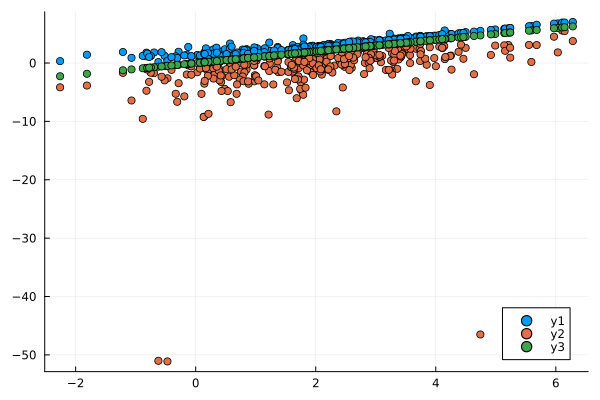

In [85]:
scatter(model.cost, model_comp.cost_sim)
scatter!(model.cost, model_coll.cost_sim)
scatter!(model.cost, model_bert.cost_sim)

##### E)

In [86]:
X_supply = hcat(ones(model.T* model.J, 1), d2["Z"], d2["w"]);
Z_supply = hcat(model.X, X_rivals, X_supply[:, 2:end]);
W_supply = inv(Z_supply' * Z_supply);

In [87]:
model_supply = blp.BLPSupply(X = X_supply, Z = Z_supply, W = W_supply);

In [88]:
model_bert_ss = deepcopy(model_ss)
model_coll_ss = deepcopy(model_ss)
model_coll_ss.Omega = ones(model_coll_ss.J, model_coll_ss.J);
model_comp_ss = deepcopy(model_ss)
model_comp_ss.Omega = zeros(model_comp_ss.J, model_comp_ss.J);

In [89]:
model_system_bert = blp.BLP(BLPDemand = model_bert_ss, BLPSupply = model_supply);
model_system_coll = blp.BLP(BLPDemand = model_coll_ss, BLPSupply = model_supply);
model_system_comp = blp.BLP(BLPDemand = model_comp_ss, BLPSupply = model_supply);

In [90]:
model_system_coll.params

0×0 Matrix{Float64}

In [91]:
model_comp_ss.Omega

3×3 Matrix{Float64}:
 0.0  0.0  0.0
 0.0  0.0  0.0
 0.0  0.0  0.0

In [92]:
model_system_bert.params

0×0 Matrix{Float64}

In [93]:
model_system_comp.opt_res

missing

In [95]:
model_system_bert = get_estimates!(model_system_bert, "model_system_bert")

Main.blp.BLP(Main.blp.BLPDemand(Main.blp.BLPData(100, 3, [1.0 0.6243472247093319 -0.3675935329234237; 1.0 0.1270525823227886 1.2737845739046483; … ; 1.0 0.1777924699713339 1.2819541386179385; 1.0 0.12895395588690017 1.3500392984244132], [6.342124353514706; 1.9304037342233142; … ; 2.3909451914239486; 1.5440226714681122;;], [5.1879758962001755e-5; 0.7184428240756918; … ; 0.19343063022875576; 0.6318247705454633;;], [-0.778340428081077 1.5860014874697206 … 1.1841193116853364 0.5825377025401334; -1.8058740935228996 0.9052572178649195 … 1.091591673538983 0.8694321550870392; … ; 1.3735359362936506 -0.2770972055353735 … -0.1220423654806788 0.8495783683864554; -0.9703732872407126 0.08268333470046725 … 0.25139606142215853 -0.04829348626510645]), 100, 3, [1.0 0.6243472247093319 -0.3675935329234237; 1.0 0.1270525823227886 1.2737845739046483; … ; 1.0 0.1777924699713339 1.2819541386179385; 1.0 0.12895395588690017 1.3500392984244132], [6.342124353514706; 1.9304037342233142; … ; 2.3909451914239486; 1.

In [96]:
model_system_comp = get_estimates!(model_system_comp, "model_system_comp")

Main.blp.BLP(Main.blp.BLPDemand(Main.blp.BLPData(100, 3, [1.0 0.6243472247093319 -0.3675935329234237; 1.0 0.1270525823227886 1.2737845739046483; … ; 1.0 0.1777924699713339 1.2819541386179385; 1.0 0.12895395588690017 1.3500392984244132], [6.342124353514706; 1.9304037342233142; … ; 2.3909451914239486; 1.5440226714681122;;], [5.1879758962001755e-5; 0.7184428240756918; … ; 0.19343063022875576; 0.6318247705454633;;], [-0.778340428081077 1.5860014874697206 … 1.1841193116853364 0.5825377025401334; -1.8058740935228996 0.9052572178649195 … 1.091591673538983 0.8694321550870392; … ; 1.3735359362936506 -0.2770972055353735 … -0.1220423654806788 0.8495783683864554; -0.9703732872407126 0.08268333470046725 … 0.25139606142215853 -0.04829348626510645]), 100, 3, [1.0 0.6243472247093319 -0.3675935329234237; 1.0 0.1270525823227886 1.2737845739046483; … ; 1.0 0.1777924699713339 1.2819541386179385; 1.0 0.12895395588690017 1.3500392984244132], [6.342124353514706; 1.9304037342233142; … ; 2.3909451914239486; 1.

In [97]:
model_system_coll = get_estimates!(model_system_coll, "model_system_coll")

Main.blp.BLP(Main.blp.BLPDemand(Main.blp.BLPData(100, 3, [1.0 0.6243472247093319 -0.3675935329234237; 1.0 0.1270525823227886 1.2737845739046483; … ; 1.0 0.1777924699713339 1.2819541386179385; 1.0 0.12895395588690017 1.3500392984244132], [6.342124353514706; 1.9304037342233142; … ; 2.3909451914239486; 1.5440226714681122;;], [5.1879758962001755e-5; 0.7184428240756918; … ; 0.19343063022875576; 0.6318247705454633;;], [-0.778340428081077 1.5860014874697206 … 1.1841193116853364 0.5825377025401334; -1.8058740935228996 0.9052572178649195 … 1.091591673538983 0.8694321550870392; … ; 1.3735359362936506 -0.2770972055353735 … -0.1220423654806788 0.8495783683864554; -0.9703732872407126 0.08268333470046725 … 0.25139606142215853 -0.04829348626510645]), 100, 3, [1.0 0.6243472247093319 -0.3675935329234237; 1.0 0.1270525823227886 1.2737845739046483; … ; 1.0 0.1777924699713339 1.2819541386179385; 1.0 0.12895395588690017 1.3500392984244132], [6.342124353514706; 1.9304037342233142; … ; 2.3909451914239486; 1.

In [98]:
model_system_coll = get_estimates!(model_system_coll, "model_system_coll")

Main.blp.BLP(Main.blp.BLPDemand(Main.blp.BLPData(100, 3, [1.0 0.6243472247093319 -0.3675935329234237; 1.0 0.1270525823227886 1.2737845739046483; … ; 1.0 0.1777924699713339 1.2819541386179385; 1.0 0.12895395588690017 1.3500392984244132], [6.342124353514706; 1.9304037342233142; … ; 2.3909451914239486; 1.5440226714681122;;], [5.1879758962001755e-5; 0.7184428240756918; … ; 0.19343063022875576; 0.6318247705454633;;], [-0.778340428081077 1.5860014874697206 … 1.1841193116853364 0.5825377025401334; -1.8058740935228996 0.9052572178649195 … 1.091591673538983 0.8694321550870392; … ; 1.3735359362936506 -0.2770972055353735 … -0.1220423654806788 0.8495783683864554; -0.9703732872407126 0.08268333470046725 … 0.25139606142215853 -0.04829348626510645]), 100, 3, [1.0 0.6243472247093319 -0.3675935329234237; 1.0 0.1270525823227886 1.2737845739046483; … ; 1.0 0.1777924699713339 1.2819541386179385; 1.0 0.12895395588690017 1.3500392984244132], [6.342124353514706; 1.9304037342233142; … ; 2.3909451914239486; 1.

In [99]:
model_system_bert.params

8×1 Matrix{Float64}:
  4.745300700261904
  0.9078559276239877
  0.9926776572206267
 -0.9253962777742148
  1.9350867558952283
  0.9136355443572618
  0.9725320169979583
  0.9217224657427552

In [ ]:
model_system_comp.params

8×1 Matrix{Float64}:
  4.745300700261904
  0.9078559276239877
  0.9926776572206267
 -0.9253962777742148
  2.950873783129857
  0.7896869202700093
  0.7755490406149562
  0.9217224657427552

In [ ]:
model_system_coll.params

8×1 Matrix{Float64}:
  4.1082521854649965
  0.7781884684366848
  0.8953530246163028
 -0.7812265570379929
 -1.140848052012854
  0.603977900141064
  0.6224920675386769
  0.7003596395119623

#### Question 10

##### A)

I am choosing the estimates including the supply side, since they increase the precision when dealing with cost estimates.


##### B)

In [ ]:
model_simul_merge = deepcopy(model_system_bert);

In [ ]:
# Changing the ownership matrix and simulating
model_simul_merge.BLPDemand.Omega = [1.0 1.0 0.0;1.0 1.0 0.0;0.0 0.0 1.0];
#model_simul_merge.BLPDemand.Omega = [1.0 1.0 1.0;1.0 1.0 1.0;1.0 1.0 1.0];
blp.simulate_BLP!(model_simul_merge.BLPDemand);

In [ ]:
model_simul_merge = blp.counterfactual_simulation(model_simul_merge);

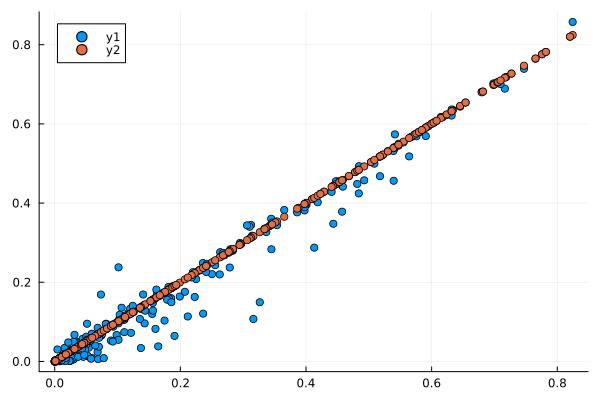

In [ ]:
#Market shares for everyone
scatter(model_system_bert.BLPDemand.shares_sim, model_simul_merge.BLPDemand.shares_sim)
scatter!(model_system_bert.BLPDemand.shares_sim, model_system_bert.BLPDemand.shares_sim)

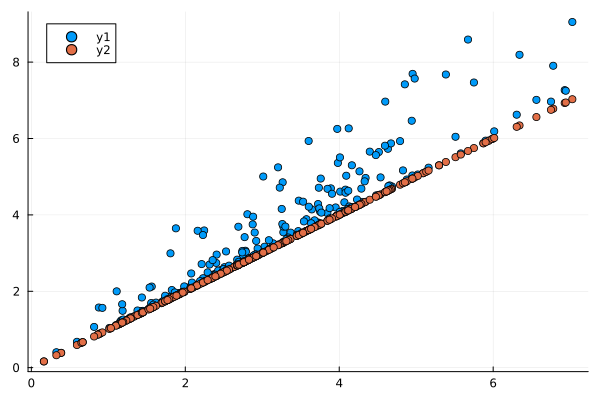

In [ ]:
#Prices
scatter(model_system_bert.BLPDemand.p, model_simul_merge.BLPDemand.p)
scatter!(model_system_bert.BLPDemand.p, model_system_bert.BLPDemand.p)

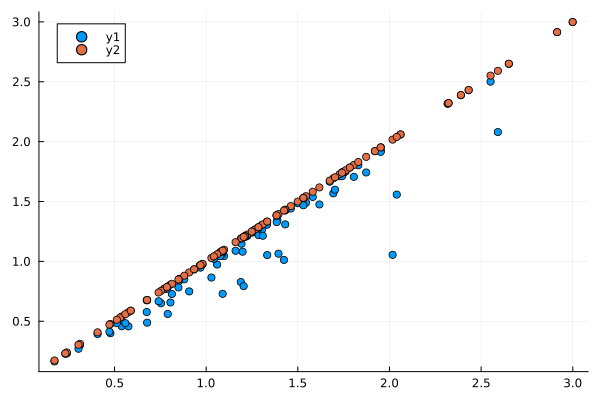

In [ ]:
#Consumer surplus
scatter(model_system_bert.BLPDemand.cs_sim, model_simul_merge.BLPDemand.cs_sim)
scatter!(model_system_bert.BLPDemand.cs_sim, model_system_bert.BLPDemand.cs_sim)

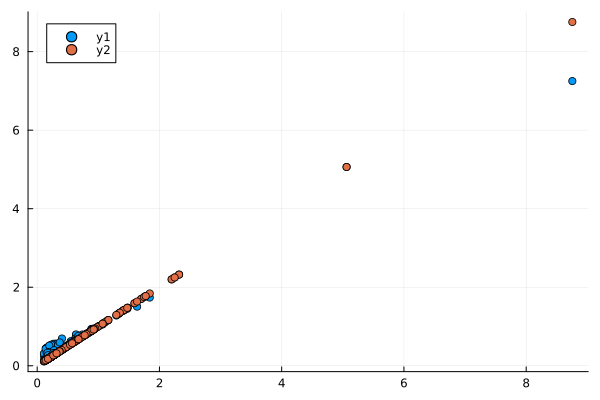

In [ ]:
#Consumer surplus
scatter(model_system_bert.BLPDemand.markup_sim, model_simul_merge.BLPDemand.markup_sim)
scatter!(model_system_bert.BLPDemand.markup_sim, model_system_bert.BLPDemand.markup_sim)

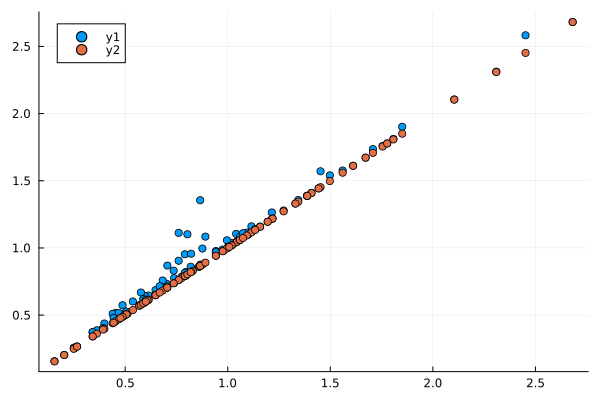

In [ ]:
#Profits
scatter(model_system_bert.BLPDemand.ps_sim, model_simul_merge.BLPDemand.ps_sim)
scatter!(model_system_bert.BLPDemand.ps_sim, model_system_bert.BLPDemand.ps_sim)

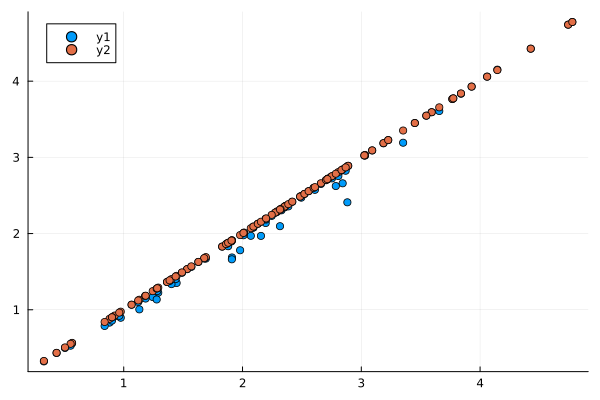

In [ ]:
#Profits
scatter(model_system_bert.BLPDemand.ts_sim, model_simul_merge.BLPDemand.ts_sim)
scatter!(model_system_bert.BLPDemand.ts_sim, model_system_bert.BLPDemand.ts_sim)

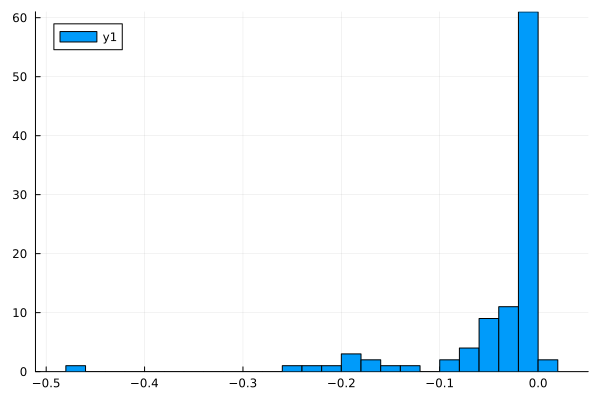

In [ ]:
# Plotting the loss of surplus
histogram(model_simul_merge.BLPDemand.ts_sim - model_system_bert.BLPDemand.ts_sim)

In [ ]:
# Diversion ratio is equal to

In [ ]:
J = 3
T = 100

100

In [ ]:
# For product one we compute the diversion ratio

idx = J * (0:T-1)

# Diversion ratio 12
D12 = model_system_bert.BLPDemand.ds_dp[1 .+ idx, 2] ./ -model_system_bert.BLPDemand.ds_dp[1 .+ idx, 1];
D21 = model_system_bert.BLPDemand.ds_dp[1 .+ idx, 2] ./ -model_system_bert.BLPDemand.ds_dp[2 .+ idx, 2];
pc1 = (model_system_bert.BLPDemand.p - model_system_bert.BLPDemand.cost_sim)[1 .+ idx]
pc2 = (model_system_bert.BLPDemand.p - model_system_bert.BLPDemand.cost_sim)[2 .+ idx]

UPP1 = D12 .* pc2;
UPP2 = D21 .* pc1;

In [ ]:
beta

3-element Vector{Int64}:
 5
 1
 1

In [ ]:
# Comouting linear approximations of impact on profits and on consumer 

# Profits is shares time increase in price
cs_sim_linear = - (UPP1 .* model_system_bert.BLPDemand.shares_sim[1 .+ idx] + UPP2 .* model_system_bert.BLPDemand.shares_sim[2 .+ idx]);
ps_sim_linear = (UPP1 .^2) .* model_system_bert.BLPDemand.shares_sim[1 .+ idx] ./ (model_system_bert.BLPDemand.p[1 .+ idx]) + (UPP2 .^2) .* model_system_bert.BLPDemand.shares_sim[2 .+ idx]
# Impact on consumers welfare
ts_sim_linear = cs_sim_linear + ps_sim_linear;


In [ ]:
Delta_cs = model_simul_merge.BLPDemand.cs_sim - model_system_bert.BLPDemand.cs_sim ;
Delta_ps = model_simul_merge.BLPDemand.ps_sim - model_system_bert.BLPDemand.ps_sim  ;
Delta_ts = model_simul_merge.BLPDemand.ts_sim - model_system_bert.BLPDemand.ts_sim ;

In [ ]:
# Price increase of product one
Delta_P1 = (model_simul_merge.BLPDemand.p - model_system_bert.BLPDemand.p)[1 .+ idx];
Delta_P2 = (model_simul_merge.BLPDemand.p - model_system_bert.BLPDemand.p)[2 .+ idx];
Delta_P3 = (model_simul_merge.BLPDemand.p - model_system_bert.BLPDemand.p)[3 .+ idx];

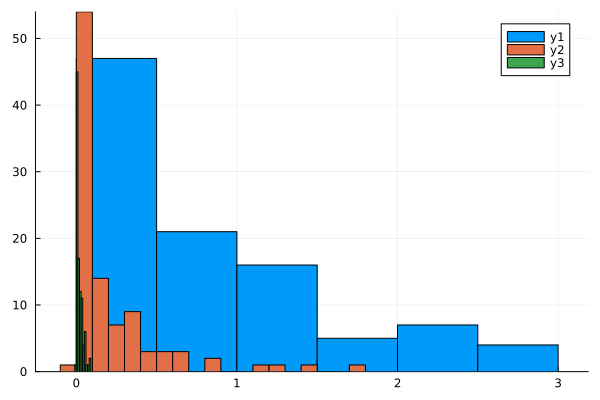

In [ ]:
histogram(Delta_P1)
histogram!(Delta_P2)
histogram!(Delta_P3)

In [ ]:
Delta_ts

100×1 Matrix{Float64}:
 -4.273608022264952e-5
 -0.001412074950577935
 -0.02311311516602066
 -0.005094598678451412
 -0.013345507572351423
 -0.04952670906633583
 -0.07969165040943094
 -0.0006412134405726633
 -7.001107501380943e-5
 -0.007500745707247347
 -0.06703864897529477
 -0.02250742192387367
 -0.0011832589440401442
  ⋮
 -0.0052298007879088
 -0.03564511258676761
 -4.680347778718286e-5
 -0.034586701910640505
 -0.0026611737267769886
 -0.010649459197496824
 -0.00031378811276217
 -0.00022746010521457194
 -0.2189776174577469
 -0.037373204511210734
 -0.0070251045001137324
 -0.0018244387160164521

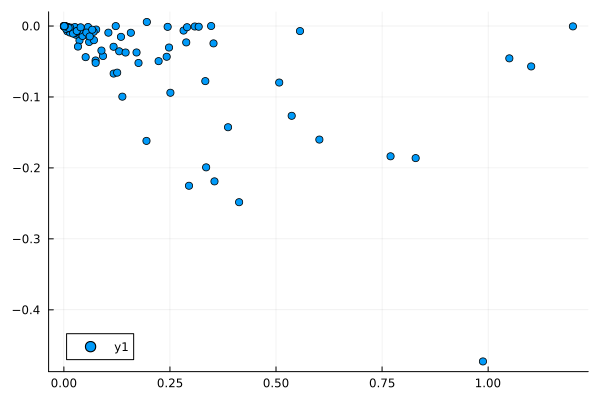

In [ ]:
scatter(UPP2, Delta_ts)

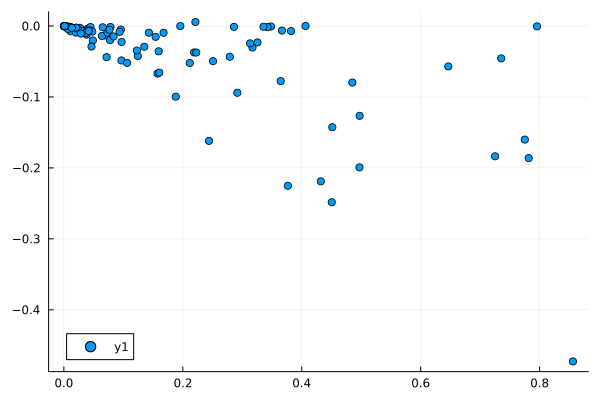

In [ ]:
scatter(D21, Delta_ts)

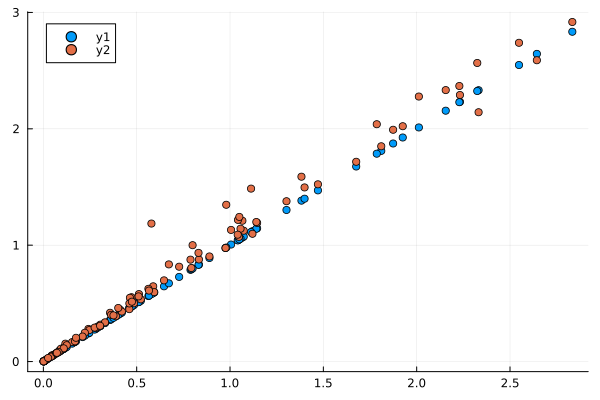

In [ ]:
scatter(UPP1, UPP1)
scatter!(UPP1, Delta_P1)

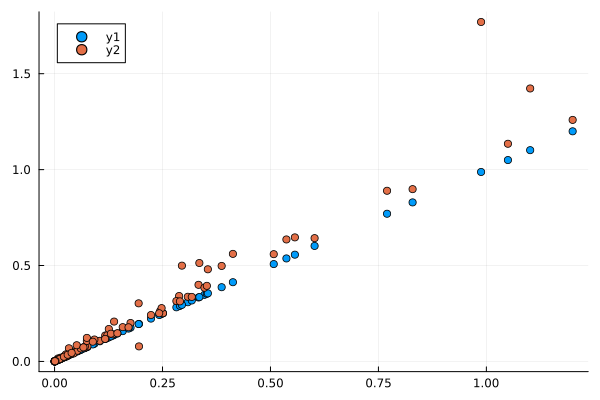

In [ ]:
scatter(UPP2, UPP2)
scatter!(UPP2, Delta_P2)

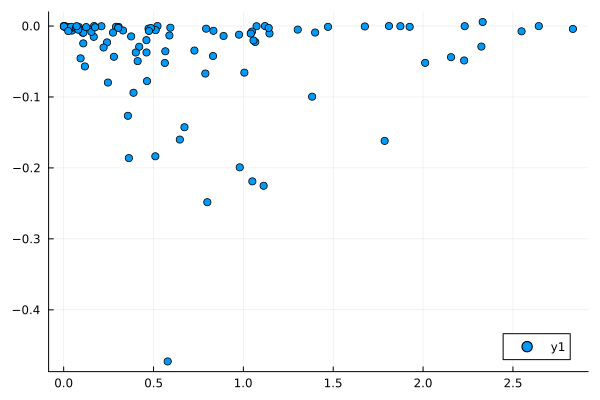

In [ ]:
scatter(UPP1, Delta_ts)

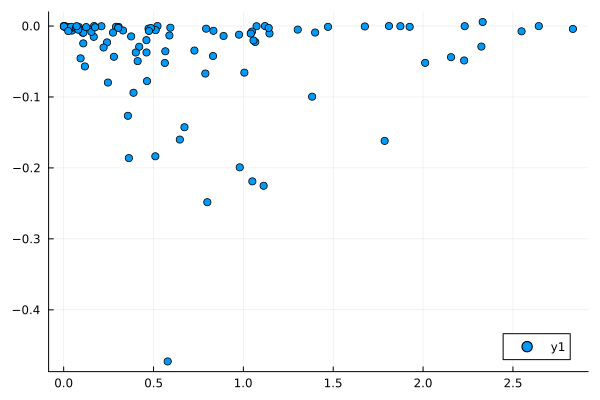

In [ ]:
scatter(UPP1, Delta_ts)

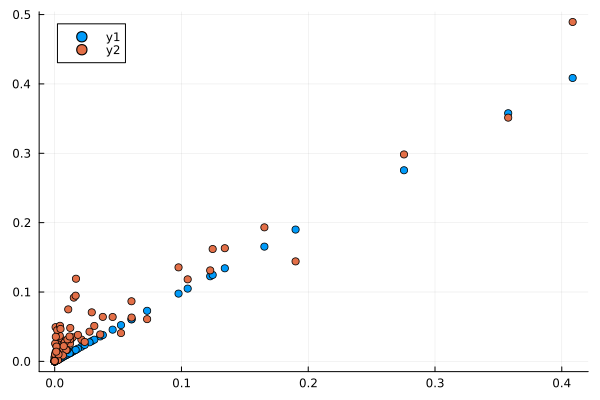

In [ ]:
scatter(ps_sim_linear, ps_sim_linear)
scatter!(ps_sim_linear, Delta_ps)

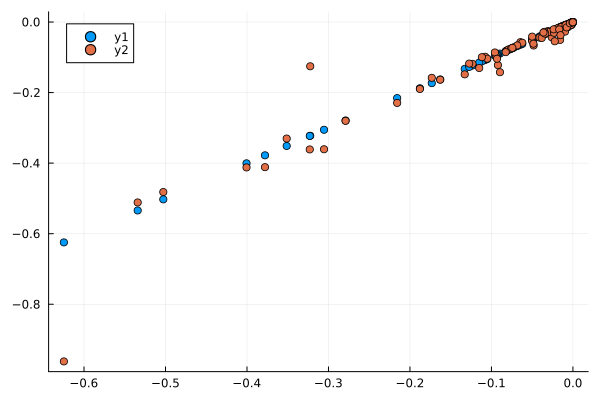

In [ ]:
scatter(cs_sim_linear, cs_sim_linear)
scatter!(cs_sim_linear, Delta_cs)

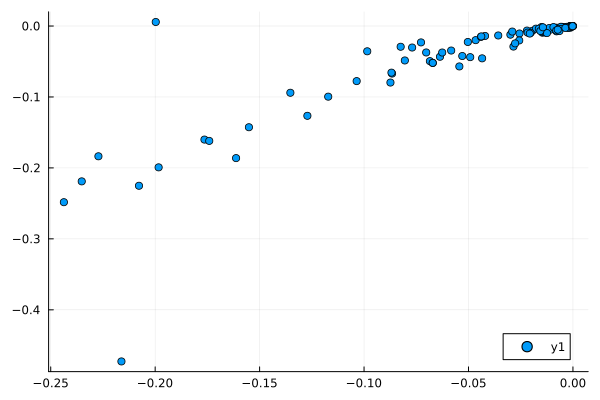

In [ ]:
scatter(ts_sim_linear, Delta_ts)

##### C)

#### Question 11

##### A)

In [ ]:


T = 100
J = 5
k = 3

gh1 = zeros(T*J, k - 1)
gh2 = zeros(T*J, k - 1)

# Computing GH instruments

for k_i in 2:k

    ref = std(model_mp.X[:, k_i])
    

    for t_i in 1:T

        idx = (t_i - 1) * J + 1:(t_i) * J;
        feat = model_mp.X[idx, k_i];
        gh1[idx, k_i - 1] = sum(abs.(feat .- feat') .< ref, dims = 2) .- 1
        gh2[idx, k_i - 1] = sum(abs.(feat .- feat') .^ 2, dims = 2)

    end

end


In [ ]:
using GLM, DataFrames, RegressionTables

In [ ]:
inst_mp_h = blp.compute_hausman(model_mp);
inst_mp_blp  = blp.compute_blp(model_mp);

In [ ]:
df = DataFrame(hcat(model_mp.p, inst_mp_h, inst_mp_blp, gh1, gh2), :auto)
rename!(df, :x1 => :price, 
            :x2 => :hausman,
            :x3 => :blp_1,
            :x4 => :blp_2,
            :x5 => :gh1_1,
            :x6 => :gh1_2,
            :x7 => :gh2_1,
            :x8 => :gh2_2
            );

In [ ]:
model1 = lm(@formula(price ~ hausman), df);
model2 = lm(@formula(price ~ blp_1 + blp_2), df);
model3 = lm(@formula(price ~ gh1_1 + gh1_2), df);
model4 = lm(@formula(price ~ gh2_1 + gh2_2), df);
model5 = lm(@formula(price ~ hausman + blp_1 + blp_2 + gh1_1 + gh1_2 + gh2_1 + gh2_2), df);

In [ ]:
regtable(model1, model2, model3, model4, model5)


------------------------------------------------------------------
                                      price                       
              ----------------------------------------------------
                   (1)        (2)        (3)        (4)        (5)
------------------------------------------------------------------
(Intercept)      0.070   1.909***   2.178***   1.715***      0.059
               (0.173)    (0.254)    (0.190)    (0.129)    (0.431)
hausman       0.963***                                    0.962***
               (0.086)                                     (0.087)
blp_1                      -0.007                           -0.039
                          (0.116)                          (0.105)
blp_2                       0.011                           -0.002
                          (0.031)                          (0.028)
gh1_1                                 -0.050                 0.074
                                     (0.059)               (0

##### B)

In [ ]:
model_mp_blp

Main.blp.BLPDemand(Main.blp.BLPData(100, 5, [1.0 0.6243472247093319 -0.36335501223223393; 1.0 0.1270525823227886 1.3722953339394266; … ; 1.0 0.503340876332152 -0.30371397143283035; 1.0 0.6557890082631682 -0.783180775296015], [0.8375286927974245; 4.005022499454276; … ; 2.025383520027014; 4.672126999854196;;], [0.7971971992815314; 0.017033753305500866; … ; 0.12474556651222765; 0.00027022172243541424;;], [-0.7165028048917169 -0.4791810519210183 … -1.0528497866079896 -0.6346869694100179; -0.4232364599976362 -1.3638669753239898 … 2.1395233071312187 2.3467279964410492; … ; -0.8169101436479812 -0.22433817455505384 … -0.8256396857921202 0.8244096432942014; -0.7622592973941856 -0.6525309953642439 … -0.4380465986883398 0.8649029968537004]), 100, 5, [1.0 0.6243472247093319 -0.36335501223223393; 1.0 0.1270525823227886 1.3722953339394266; … ; 1.0 0.503340876332152 -0.30371397143283035; 1.0 0.6557890082631682 -0.783180775296015], [0.8375286927974245; 4.005022499454276; … ; 2.025383520027014; 4.67212

In [ ]:
model_mp_blp = deepcopy(model_mp)
model_mp_gh = deepcopy(model_mp)

model_mp_blp.Z = hcat(model_mp_blp.X, inst_mp_blp);
model_mp_blp.W = inv(model_mp_blp.Z' * model_mp_blp.Z);

model_mp_gh.Z = hcat(model_mp_gh.X, gh1, gh2);
model_mp_gh.W = inv(model_mp_gh.Z' * model_mp_gh.Z);

In [ ]:
model_mp_gh = get_estimates!(model_mp_gh, "model_mp_gh_");
model_mp_blp = get_estimates!(model_mp_blp, "model_mp_blp_");

Reached max number of iterations
Reached max number of iterations
Reached max number of iterations
Reached max number of iterations
Reached max number of iterations
Reached max number of iterations
Reached max number of iterations
Reached max number of iterations
Reached max number of iterations
Reached max number of iterations
Reached max number of iterations
Reached max number of iterations
Reached max number of iterations
Reached max number of iterations
Reached max number of iterations
Reached max number of iterations
Reached max number of iterations
Reached max number of iterations
Reached max number of iterations
Reached max number of iterations
Reached max number of iterations
Reached max number of iterations
Reached max number of iterations
Reached max number of iterations
Reached max number of iterations
Reached max number of iterations
Reached max number of iterations
Reached max number of iterations
Reached max number of iterations
Reached max number of iterations
Reached ma

LoadError: InterruptException:

Reached max number of iterations
Reached max number of iterations
Reached max number of iterations
Reached max number of iterations


In [ ]:
model_mp_gh = deepcopy(model_mp)

Main.blp.BLPDemand(Main.blp.BLPData(100, 5, [1.0 0.6243472247093319 -0.36335501223223393; 1.0 0.1270525823227886 1.3722953339394266; … ; 1.0 0.503340876332152 -0.30371397143283035; 1.0 0.6557890082631682 -0.783180775296015], [0.8375286927974245; 4.005022499454276; … ; 2.025383520027014; 4.672126999854196;;], [0.7971971992815314; 0.017033753305500866; … ; 0.12474556651222765; 0.00027022172243541424;;], [-0.7165028048917169 -0.4791810519210183 … -1.0528497866079896 -0.6346869694100179; -0.4232364599976362 -1.3638669753239898 … 2.1395233071312187 2.3467279964410492; … ; -0.8169101436479812 -0.22433817455505384 … -0.8256396857921202 0.8244096432942014; -0.7622592973941856 -0.6525309953642439 … -0.4380465986883398 0.8649029968537004]), 100, 5, [1.0 0.6243472247093319 -0.36335501223223393; 1.0 0.1270525823227886 1.3722953339394266; … ; 1.0 0.503340876332152 -0.30371397143283035; 1.0 0.6557890082631682 -0.783180775296015], [0.8375286927974245; 4.005022499454276; … ; 2.025383520027014; 4.67212

In [ ]:
model_mp_est.Z = hcat(model_mp_est.X, inst_mp_h, gh1, gh2);
model_mp_est.W = inv(model_mp_est.Z' * model_mp_est.Z);

In [ ]:
model_mp_est = get_estimates!(model_mp_est, "model_mp_gh");

Main.blp.BLPDemand(Main.blp.BLPData(100, 5, [1.0 0.6243472247093319 -0.36335501223223393; 1.0 0.1270525823227886 1.3722953339394266; … ; 1.0 0.503340876332152 -0.30371397143283035; 1.0 0.6557890082631682 -0.783180775296015], [0.8375286927974245; 4.005022499454276; … ; 2.025383520027014; 4.672126999854196;;], [0.7971971992815314; 0.017033753305500866; … ; 0.12474556651222765; 0.00027022172243541424;;], [-0.7165028048917169 -0.4791810519210183 … -1.0528497866079896 -0.6346869694100179; -0.4232364599976362 -1.3638669753239898 … 2.1395233071312187 2.3467279964410492; … ; -0.8169101436479812 -0.22433817455505384 … -0.8256396857921202 0.8244096432942014; -0.7622592973941856 -0.6525309953642439 … -0.4380465986883398 0.8649029968537004]), 100, 5, [1.0 0.6243472247093319 -0.36335501223223393; 1.0 0.1270525823227886 1.3722953339394266; … ; 1.0 0.503340876332152 -0.30371397143283035; 1.0 0.6557890082631682 -0.783180775296015], [0.8375286927974245; 4.005022499454276; … ; 2.025383520027014; 4.67212

In [ ]:
semielas = zeros(T * J, 1)
ownelas = zeros(T * J, 1)

for t_i in 1:T
    

    idx = (t_i - 1) * J + 1: t_i * J
    semielas[idx] = diag(model_mp_est.ds_dp[idx, :]) ./ model_mp_est.shares[idx, :];
    ownelas[idx] = diag(model_mp_est.elas_sim[idx, :]);
    

end
#.Compute semielasticities



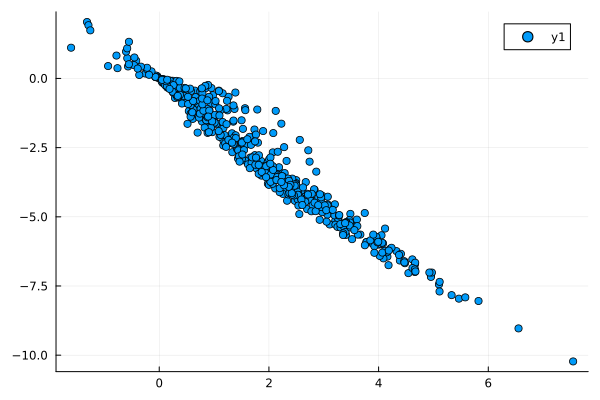

In [ ]:
# Check elasticities as a function of the price
scatter(model_mp_est.p, ownelas)

In [ ]:
i_scp = (mean(model_mp_est.choice .^4, dims = 2) ./ (mean(model_mp_est.choice, dims = 2) .^2) * mean((model_mp_est.beta[end] .- exp.(model_mp_est.errors * model_mp_est.sigma)) .^ 2)) .^ 0.5;

df_semielas = DataFrame(hcat(semielas, model_mp_est.p, model_mp_est.X, i_scp), :auto)
rename!(df_semielas, :x1 => :semielas,
                     :x2 => :price,
                     :x3 => :x0,
                     :x4 => :x1,
                     :x5 => :x2,
                     :x6 => :i_scp
);
model = lm(@formula( semielas ~ x1 + x2 + price + 1/price + 1/x1 + 1/x2 + x1 ^2+ x2 ^ 2), df_semielas);
# Second order approximation works
df_semielas.semielas_p = predict(model);
df_semielas.error =df_semielas.semielas - df_semielas.semielas_p;




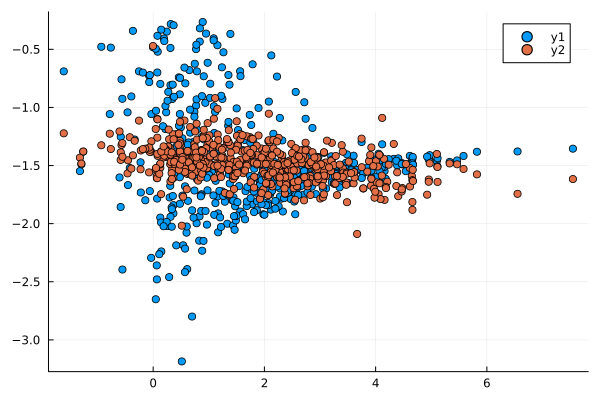

In [ ]:
scatter(df_semielas.price, df_semielas.semielas)
scatter!(df_semielas.price, df_semielas.semielas_p)

In [ ]:
maximum(abs.(vec(mean(model_mp_est.choice, dims = 2)) .- model_mp_est.shares))

0.0002872122214567785

500-element Vector{Float64}:
 -5.875195241804274
 -0.20558699326865906
 -0.06795194347651652
 -0.38722936789726087
 -0.11538223909094888
 -0.3725085945927047
 -3.09902743165581
 -1.8595627251727596
 -0.003781497003684266
 -0.00992131312920115
 -0.03114194233989854
 -4.130898155967329
 -0.16966873881153144
  ⋮
 -0.5469963381462253
 -0.843370860683416
 -0.10184302641389315
 -0.29649296621340065
 -0.2683099715243858
 -0.12961426301938833
 -1.9251305677894825
 -0.15488414776854478
 -0.1313568907774915
 -5.36824359539962
 -0.46411602531181345
 -0.004282100702120898

In [ ]:
df_semielas_r1 = df_semielas[(abs.(df_semielas.i_scp ./ df_semielas.semielas )).< 0.1,:];
df_semielas_r2 = df_semielas[(abs.(df_semielas.i_scp ./ df_semielas.semielas )).< 0.25,:];
df_semielas_r3 = df_semielas[(abs.(df_semielas.i_scp ./ df_semielas.semielas )).< 0.5,:];
df_semielas_r4 = df_semielas[(abs.(df_semielas.i_scp ./ df_semielas.semielas )).< 0.75,:];
df_semielas_r5 = df_semielas[(abs.(df_semielas.i_scp ./ df_semielas.semielas )).< 1,:];
df_semielas_r6 = df_semielas[(abs.(df_semielas.i_scp ./ df_semielas.semielas )).< 2,:];

model_r1 = lm(@formula( semielas ~ x1 + x2 + price + 1/price + 1/x1 + 1/x2 + x1 ^2+ x2 ^ 2), df_semielas_r1);
model_r2 = lm(@formula( semielas ~ x1 + x2 + price + 1/price + 1/x1 + 1/x2 + x1 ^2+ x2 ^ 2), df_semielas_r2);
model_r3 = lm(@formula( semielas ~ x1 + x2 + price + 1/price + 1/x1 + 1/x2 + x1 ^2+ x2 ^ 2), df_semielas_r3);
model_r4 = lm(@formula( semielas ~ x1 + x2 + price + 1/price + 1/x1 + 1/x2 + x1 ^2+ x2 ^ 2), df_semielas_r4);
model_r5 = lm(@formula( semielas ~ x1 + x2 + price + 1/price + 1/x1 + 1/x2 + x1 ^2+ x2 ^ 2), df_semielas_r5);
model_r6 = lm(@formula( semielas ~ x1 + x2 + price + 1/price + 1/x1 + 1/x2 + x1 ^2+ x2 ^ 2), df_semielas_r6);
# Second order approximation works
df_semielas_r1.semielas_p = predict(model_r1);
df_semielas_r2.semielas_p = predict(model_r2);
df_semielas_r3.semielas_p = predict(model_r3);
df_semielas_r4.semielas_p = predict(model_r4);
df_semielas_r5.semielas_p = predict(model_r5);
df_semielas_r6.semielas_p = predict(model_r6);





In [ ]:
regtable(
        model_r1, 
        model_r2, 
        model_r3, 
        model_r4, 
        model_r5, 
        model_r6,
        model

)


-----------------------------------------------------------------------------------------------
                                                   semielas                                    
              ---------------------------------------------------------------------------------
                    (1)         (2)         (3)         (4)         (5)         (6)         (7)
-----------------------------------------------------------------------------------------------
(Intercept)   -1.902***   -2.023***   -1.989***   -1.906***   -1.860***   -1.761***   -1.556***
                (0.041)     (0.036)     (0.035)     (0.035)     (0.038)     (0.049)     (0.072)
x1               -0.130      -0.020       0.090       0.018       0.098       0.307      0.612*
                (0.140)     (0.130)     (0.126)     (0.131)     (0.142)     (0.183)     (0.275)
x2               0.028*     0.032**    0.044***    0.054***    0.065***    0.092***    0.121***
                (0.013)     (0.012)    

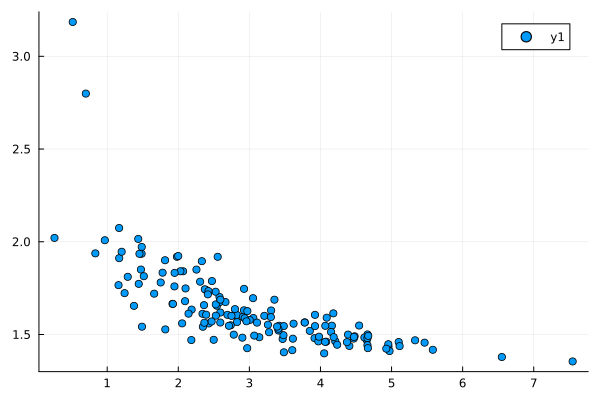

In [ ]:
scatter(df_semielas_r.price, -df_semielas_r.semielas)

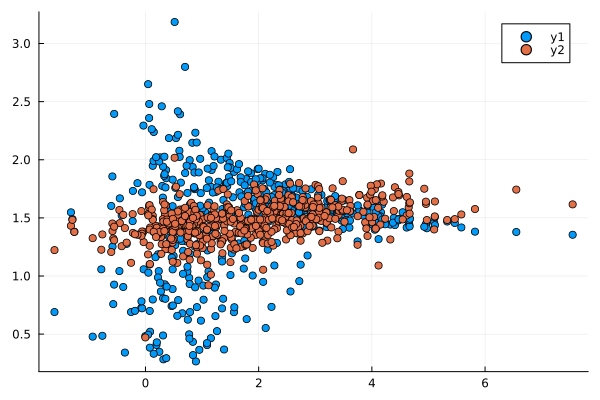

In [ ]:
scatter(df_semielas.price, -df_semielas.semielas)
scatter!(df_semielas.price, -df_semielas.semielas_p)

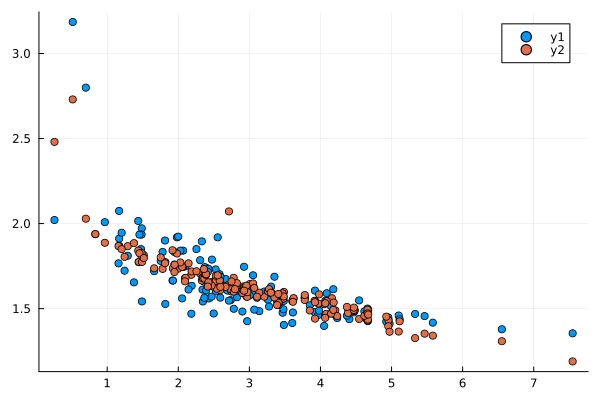

In [ ]:
scatter(df_semielas_r.price, -df_semielas_r.semielas)
scatter!(df_semielas_r.price, -df_semielas_r.semielas_p)

Row,semielas,price,x0,x1,x2,i_scp,semielas_p,error
,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64
1,-1.49926,4.00502,1.0,0.127053,1.3723,0.191378,-1.48017,-0.0190813
2,-2.00044,1.33284,1.0,0.831763,-0.518792,0.128364,-1.48519,-0.515243
3,-1.53486,3.88234,1.0,0.802276,0.504378,0.111992,-1.4596,-0.0752568
4,-1.50047,4.66199,1.0,0.0619061,-1.62294,0.00332958,-1.90551,0.405036
5,-1.56559,3.77834,1.0,0.231617,-0.952148,0.0102731,-1.70985,0.144257
6,-1.9116,1.16892,1.0,0.553895,-0.647076,0.0534512,-1.47844,-0.433165
7,-2.23885,0.146497,1.0,0.202199,0.741821,0.360711,-1.37162,-0.867229
8,-1.85033,1.47473,1.0,0.355198,-1.2497,0.007281,-1.59577,-0.254558
9,-1.39832,4.05236,1.0,0.167165,-1.05085,9.52889e-5,-1.76348,0.365152


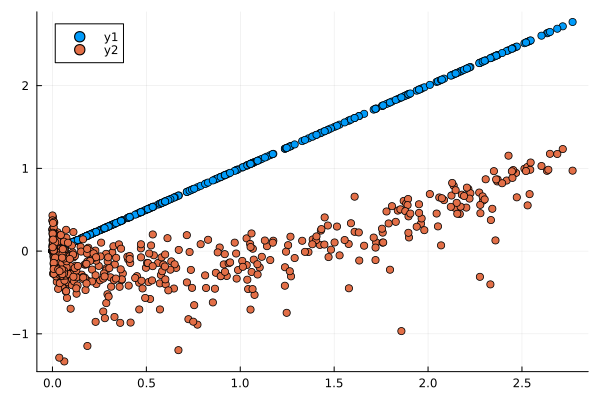

In [ ]:
scatter(df_semielas.i_scp, df_semielas.i_scp)
scatter!(df_semielas.i_scp, df_semielas.error)

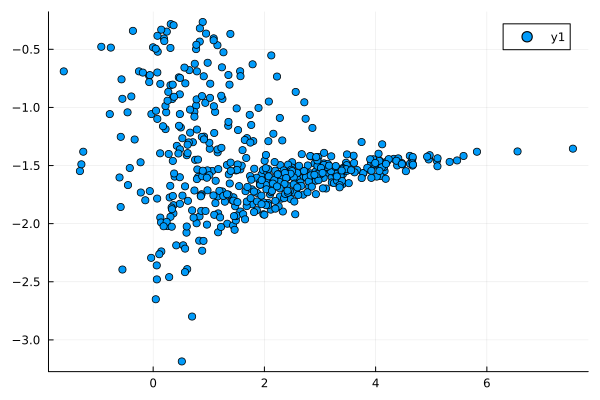

In [ ]:
# Check the semilasticities
scatter(model_mp_est.p, semielas)

In [ ]:
 scp_ 

500×1 Matrix{Float64}:
 2.513306103694194
 0.19137807508812651
 0.12836386195852917
 0.4713897910799298
 0.11199163474103216
 0.4034229391814361
 2.293325069984779
 1.608906675923734
 0.003329581854529007
 0.010273092828250726
 0.05345118888355451
 2.342065147311873
 0.36071064096866495
 ⋮
 1.0546661882567596
 0.9459643288270174
 0.13523465616880387
 0.36535056668597365
 0.4111716930800277
 0.20060854505529713
 1.6090067422115695
 0.18090712998159755
 0.18132291529914468
 2.4463713398541236
 0.6001535641069186
 0.0036718042089627584

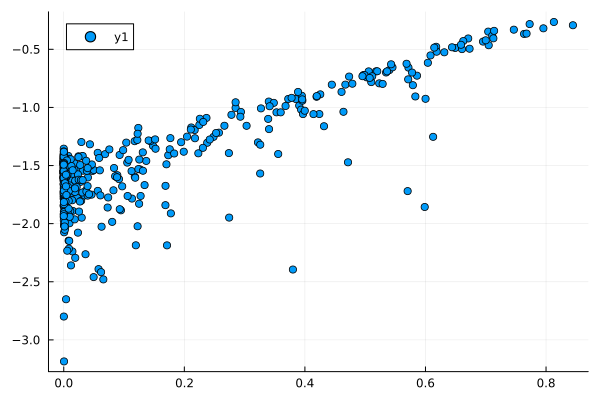

In [ ]:
scatter(scp_, semielas)

In [ ]:
scp_

500×1 Matrix{Float64}:
 2.513306103694194
 0.19137807508812651
 0.12836386195852917
 0.4713897910799298
 0.11199163474103216
 0.4034229391814361
 2.293325069984779
 1.608906675923734
 0.003329581854529007
 0.010273092828250726
 0.05345118888355451
 2.342065147311873
 0.36071064096866495
 ⋮
 1.0546661882567596
 0.9459643288270174
 0.13523465616880387
 0.36535056668597365
 0.4111716930800277
 0.20060854505529713
 1.6090067422115695
 0.18090712998159755
 0.18132291529914468
 2.4463713398541236
 0.6001535641069186
 0.0036718042089627584

9.082246764327305

##### C)




##### D)

In [ ]:
T = 100;
J = 5;
R = 500;

t_i = 1;
r_i = 15;

D_matrix = zeros(T*J, J);
m_rank = zeros(T, 1);
erank = zeros(T, 1);

for t_i in 1:T

    idx = (t_i-1)*J + 1 : t_i*J;
    S = model_mp_est.shares[idx] ;
    model_mp_est.shares_sim[idx] ;


    for r_i in 1:R

        C = model_mp_est.choice[idx, r_i] ;
        D_matrix[idx, :] += (C' ./ (1 .- C)) .* (C / R) ./ S;
        m_rank[t_i] = LinearAlgebra.rank(D_matrix[idx, :]);
        # Getting number of eigenvalues 
        sv, _ = eigen(D_matrix[idx, :]);
        #print(sv)
        sv = max.(real(sv), 0);

        p = sv / sum(sv);
        
        # Effective ranking
        erank[t_i] = exp(sum(-(p .* log.( p .+ 1e-300))))

    end
end

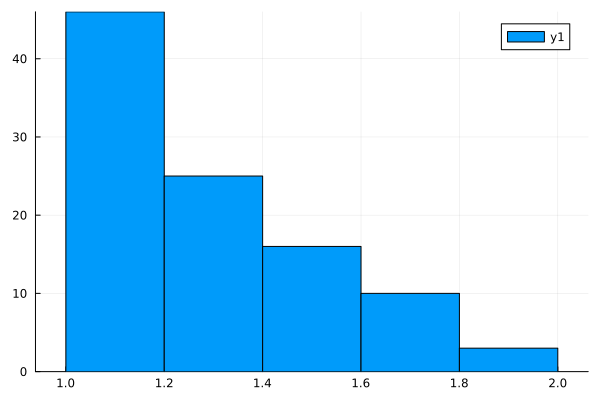

In [ ]:
histogram(erank)

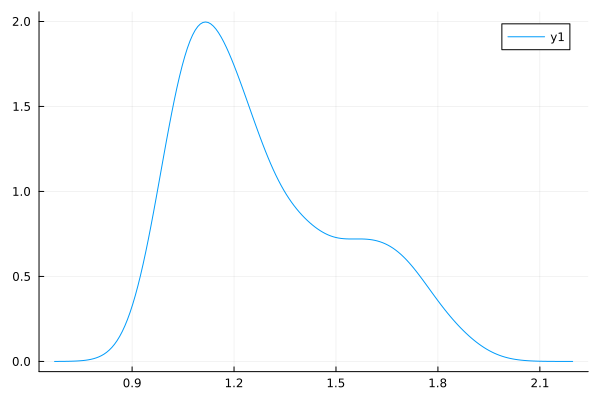

In [ ]:
density(erank)